# 07 - Model Comparison

Final leaderboard.


## Setup

In [1]:
import sys, json
sys.path.insert(0, r"D:\\Projects\\done\\eth_bot\\eth_bot_v2")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PRED_DIR = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "reports" / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
for f in sorted(PRED_DIR.glob("*.json")):
    print(f"  {f.name:<24} {f.stat().st_size:>7} bytes")

  baseline.json                324 bytes
  lstm.json                    363 bytes


## 1. Load results

In [2]:
def load(name):
    p = PRED_DIR / name
    return json.loads(p.read_text()) if p.exists() else None

rows = []

b = load("baseline.json")
if b:
    rows.append({"model": "baseline",
                 "rmse": b["return"]["rmse"],
                 "mae":  b["return"]["mae"],
                 "dir_accuracy": b["return"]["dir_accuracy"]})

l = load("linear.json")
if l:
    rows.append({"model": "linear",
                 "rmse": l["rmse"], "mae": l["mae"],
                 "dir_accuracy": l["dir_accuracy"]})

t = load("trees.json")
if t:
    for m in t.get("models", []):
        rows.append({"model": m["model"], "rmse": m["rmse"],
                     "mae": m["mae"], "dir_accuracy": m["dir_accuracy"]})

n = load("lstm.json")
if n and isinstance(n.get("rmse"), (int, float)) and not np.isnan(n["rmse"]):
    rows.append({"model": "lstm", "rmse": n["rmse"],
                 "mae": n["mae"], "dir_accuracy": n["dir_accuracy"]})

w = load("walkforward.json")
if w:
    for name, info in w.get("models", {}).items():
        for r in rows:
            if r["model"].lower() == name.lower():
                r["beat_rate"] = info.get("win_rate")
                break

df = pd.DataFrame(rows).sort_values("rmse").reset_index(drop=True)
df

,model,rmse,mae,dir_accuracy
0,lstm,0.031971,0.021341,0.557823
1,baseline,0.032920,0.021931,0.520000


## 2. Bar charts

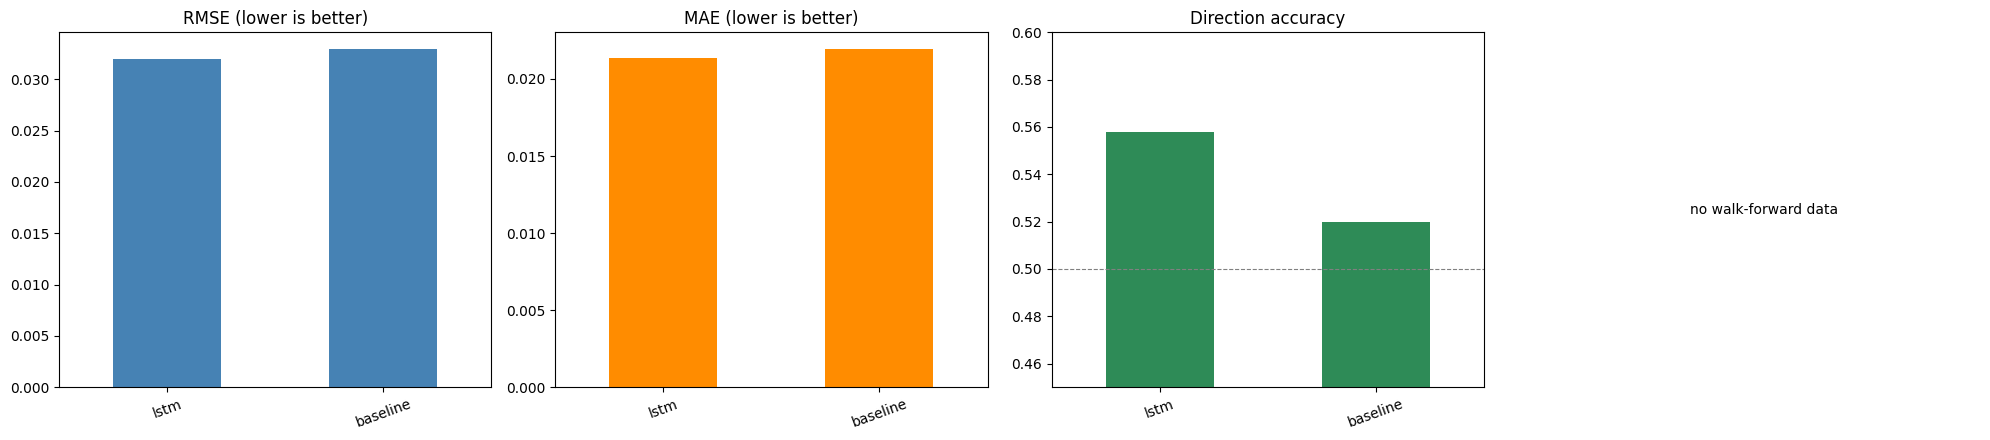

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
df_sorted = df.sort_values("rmse")

df_sorted.plot.bar(x="model", y="rmse", ax=axes[0], color="steelblue", legend=False)
axes[0].set_title("RMSE (lower is better)"); axes[0].set_xlabel("")

df_sorted.plot.bar(x="model", y="mae", ax=axes[1], color="darkorange", legend=False)
axes[1].set_title("MAE (lower is better)"); axes[1].set_xlabel("")

df_sorted.plot.bar(x="model", y="dir_accuracy", ax=axes[2], color="seagreen", legend=False)
axes[2].axhline(0.5, ls="--", color="gray", lw=0.8)
axes[2].set_title("Direction accuracy"); axes[2].set_ylim(0.45, 0.60); axes[2].set_xlabel("")

if "beat_rate" in df_sorted.columns and df_sorted["beat_rate"].notna().any():
    df_sorted.plot.bar(x="model", y="beat_rate", ax=axes[3], color="purple", legend=False)
    axes[3].axhline(0.5, ls="--", color="gray", lw=0.8)
    axes[3].axhline(0.55, ls=":", color="black", lw=0.8)
    axes[3].set_title("Walk-forward beat rate"); axes[3].set_ylim(0.0, 1.0); axes[3].set_xlabel("")
else:
    axes[3].text(0.5, 0.5, "no walk-forward data", ha="center", va="center")
    axes[3].set_axis_off()

for a in axes:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 3. Verdict

In [4]:
print("=" * 60)
print("VERDICT")
print("=" * 60)
if df.empty:
    print("no results loaded")
else:
    best_rmse = df.sort_values("rmse").iloc[0]
    print(f"\nbest by RMSE: {best_rmse['model']}  rmse={best_rmse['rmse']:.6f}  dir={best_rmse['dir_accuracy']:.2%}")

    best_beat = None
    if "beat_rate" in df.columns and df["beat_rate"].notna().any():
        best_beat = df.sort_values("beat_rate", ascending=False).iloc[0]
        print(f"best by beat: {best_beat['model']}  beat={best_beat['beat_rate']:.2%}  dir={best_beat['dir_accuracy']:.2%}")

    print("-" * 60)
    if best_beat is not None:
        br = best_beat["beat_rate"]; da = best_beat["dir_accuracy"]
        if br >= 0.60 and da >= 0.53:
            print("VERDICT: real edge")
        elif br >= 0.55:
            print("VERDICT: marginal edge")
        else:
            print("VERDICT: no reliable edge")
    else:
        base = df.loc[df["model"] == "baseline"]
        if len(base):
            imp = (base.iloc[0]["rmse"] - best_rmse["rmse"]) / base.iloc[0]["rmse"]
            print(f"RMSE improvement over baseline: {imp:+.2%}")
            if imp > 0.05:
                print("VERDICT: promising, needs walk-forward")
            elif imp > 0.02:
                print("VERDICT: marginal")
            else:
                print("VERDICT: no meaningful edge")
    print("=" * 60)

VERDICT

best by RMSE: lstm  rmse=0.031971  dir=55.78%
------------------------------------------------------------
RMSE improvement over baseline: +2.88%
VERDICT: marginal


## 4. Save leaderboard

In [5]:
out = {
    "models": df.replace({np.nan: None}).to_dict(orient="records"),
    "best_rmse": df.sort_values("rmse").iloc[0]["model"] if not df.empty else None,
}
path = PRED_DIR / "leaderboard.json"
path.write_text(json.dumps(out, indent=2, default=str), encoding="utf-8")
print("wrote", path)
print()
print(df.to_string(index=False))

wrote D:\Projects\done\eth_bot\eth_bot_v2\reports\predictions\leaderboard.json

   model     rmse      mae  dir_accuracy
    lstm 0.031971 0.021341      0.557823
baseline 0.032920 0.021931      0.520000
